# 4.1 Thực nghiệm K-Means với dữ liệu 2 chiều đơn giản
# (Lưu ý: Tự cài đặt từng bước - không dùng thư viện scikit-learn)
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)

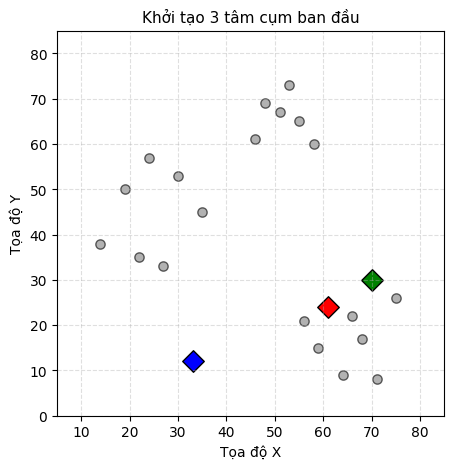

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Khởi tạo tập dữ liệu 2 chiều (20 điểm)
df = pd.DataFrame({
    'x': [14, 22, 19, 27, 30, 35, 24, 46, 48, 53, 55, 58, 51, 56, 59, 64, 66, 71, 75, 68],
    'y': [38, 35, 50, 33, 53, 45, 57, 61, 69, 73, 65, 60, 67, 21, 15, 9, 22, 8, 26, 17]
})

# 2. Khởi tạo ngẫu nhiên 3 tâm cụm ban đầu
np.random.seed(42)
k = 3
centroids = {i + 1: [np.random.randint(10, 80), np.random.randint(10, 80)] for i in range(k)}
colmap = {1: 'red', 2: 'green', 3: 'blue'}

# 3. Hàm vẽ biểu đồ trực quan hóa dữ liệu và tâm cụm
def plot_clusters():
    plt.figure(figsize=(5, 5))
    plt.scatter(df['x'], df['y'], color=df.get('color', 'gray'), alpha=0.6, edgecolor='k', s=45)
    for i in centroids:
        plt.scatter(*centroids[i], color=colmap[i], s=120, edgecolor='black', marker='D')
    plt.xlim(5, 85)
    plt.ylim(0, 85)
    plt.title('Khởi tạo 3 tâm cụm ban đầu', fontsize=11)
    plt.xlabel('Tọa độ X')
    plt.ylabel('Tọa độ Y')
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.show()

plot_clusters()

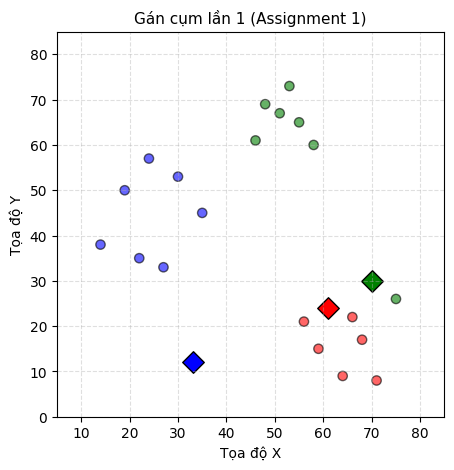

In [2]:
# BƯỚC 1: Gán mỗi điểm dữ liệu về tâm cụm gần nhất
def assignment(data, c):
    for i in c:
        # Tính khoảng cách Euclidean: sqrt((x - c_x)^2 + (y - c_y)^2)
        data[f'd_{i}'] = np.sqrt((data['x'] - c[i][0])**2 + (data['y'] - c[i][1])**2)
    
    # Xác định tâm cụm có khoảng cách nhỏ nhất
    data['closest'] = data[[f'd_{i}' for i in c]].idxmin(axis=1).str[-1].astype(int)
    data['color'] = data['closest'].map(colmap)
    return data

df = assignment(df, centroids)
plot_clusters()

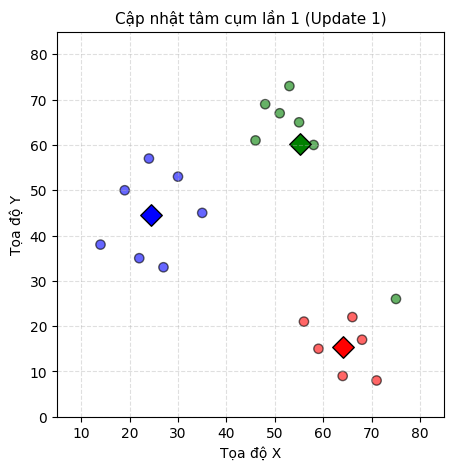

In [3]:
# BƯỚC 2: Cập nhật lại tọa độ tâm cụm bằng trung bình cộng các điểm trong cụm
def update(data, c):
    for i in c:
        sub = data[data['closest'] == i]
        if len(sub) > 0:
            c[i] = [sub['x'].mean(), sub['y'].mean()]
    return c

centroids = update(df, centroids)
plot_clusters()

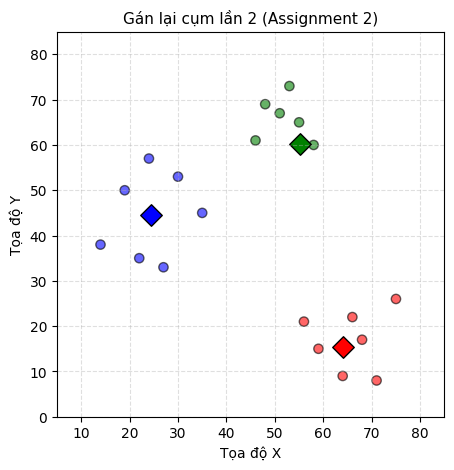

In [4]:
# BƯỚC 3: Gán lại cụm theo các vị trí tâm cụm mới
df = assignment(df, centroids)
plot_clusters()

Thuật toán K-Means đã hội tụ sau 3 vòng lặp!


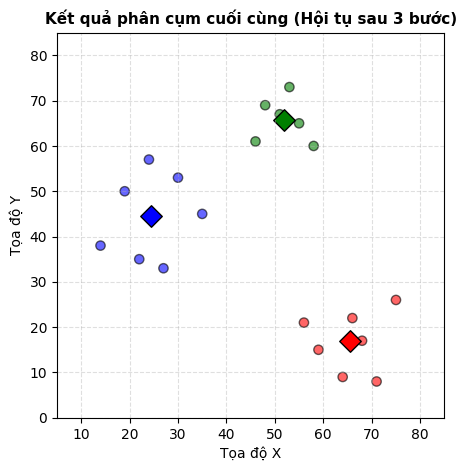

In [5]:
# BƯỚC 4: Lặp lại quá trình Update và Assignment cho đến khi thuật toán hội tụ
iteration = 2
while True:
    old_closest = df['closest'].copy()
    centroids = update(df, centroids)
    df = assignment(df, centroids)
    iteration += 1
    # Dừng vòng lặp khi nhãn cụm của tất cả các điểm không còn thay đổi
    if df['closest'].equals(old_closest):
        print(f"Thuật toán K-Means đã hội tụ sau {iteration} vòng lặp!")
        break

plot_clusters()